# Hotel Review Sentiment Analysis

## 1. Project Introduction

This project predicts whether a hotel review is **positive, negative, or neutral**. It uses TF-IDF and Logistic Regression. SIA (VADER) is also tested as a second opinion.


## 2. Load and Inspect the Dataset


In [1]:
import numpy as np
import pandas as pd

data = pd.read_csv("Book1.csv")
data = data.drop(columns=["Unnamed: 0"], errors="ignore")

print(data.shape)
print(data["result"].value_counts())
display(data.head())


(20491, 2)
result
positive    18831
negative     1569
neutral        91
Name: count, dtype: int64


,Review,result
0,nice hotel expensive parking got good deal sta...,positive
1,ok nothing special charge diamond member hilto...,positive
2,nice rooms not 4* experience hotel monaco seat...,positive
3,"unique, great stay, wonderful time hotel monac...",positive
4,"great stay great stay, went seahawk game aweso...",positive


## 3. Clean the Data


In [2]:
data = data.dropna(subset=["Review", "result"])
data["Review"] = data["Review"].astype(str).str.strip()
data["result"] = data["result"].astype(str).str.strip().str.lower()
data = data[data["Review"] != ""]

X = data["Review"]
y = data["result"]

print("Rows after cleaning:", len(data))


Rows after cleaning: 20491


## 4. Split the Data and Use TF-IDF

The test data is kept aside so it can be used to check the model after training.


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

vectorizer = TfidfVectorizer(max_features=10000)
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Training reviews:", len(X_train))
print("Test reviews:", len(X_test))


Training reviews: 16392
Test reviews: 4099


## 5. Train Logistic Regression


In [4]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(class_weight="balanced", max_iter=1000)
model.fit(X_train_tfidf, y_train)

print("Model training complete.")


Model training complete.


## 6. Combine Logistic Regression with SIA

Logistic Regression score = positive probability − negative probability. SIA gives a score between -1 and +1. We take the **mean of the two scores**. Scores above 0.05 are positive, below -0.05 are negative, and the scores in between are neutral.


In [5]:
import nltk
from nltk.sentiment import SentimentIntensityAnalyzer

try:
    sia = SentimentIntensityAnalyzer()
except LookupError:
    nltk.download("vader_lexicon")
    sia = SentimentIntensityAnalyzer()

positive_index = list(model.classes_).index("positive")
negative_index = list(model.classes_).index("negative")

def get_sentiment(score):
    if score > 0.05:
        return "positive"
    elif score < -0.05:
        return "negative"
    else:
        return "neutral"

def get_hybrid_prediction(review, probabilities):
    lr_score = probabilities[positive_index] - probabilities[negative_index]
    sia_score = sia.polarity_scores(review)["compound"]
    mean_score = (lr_score + sia_score) / 2
    return get_sentiment(mean_score)


## 7. Save the Model and Vectorizer


In [6]:
import joblib

joblib.dump(model, "sentiment_model.joblib")
joblib.dump(vectorizer, "tfidf_vectorizer.joblib")

print("Model and vectorizer saved.")


Model and vectorizer saved.


## 8. Enter a Review and Predict Its Sentiment


In [11]:
review = input("Enter a hotel review: ").strip()

if review:
    review_features = vectorizer.transform([review])
    probabilities = model.predict_proba(review_features)[0]

    print("Logistic Regression:", model.predict(review_features)[0])
    print("Hybrid prediction:", get_hybrid_prediction(review, probabilities))
else:
    print("Please enter a review.")


Logistic Regression: neutral
Hybrid prediction: positive


## 9. Model Evaluation and Performance

The Logistic Regression model achieved **92.07% accuracy** and a **0.53 macro F1-score**. Although the accuracy is high, the lower macro F1-score indicates that the model does not perform equally well across all sentiment classes. In particular, the model failed to correctly identify any neutral reviews in the test set. This is likely due to the strong class imbalance in the dataset, which contains very few neutral examples. Therefore, accuracy alone is not sufficient to judge the model's performance.

In [8]:
from sklearn.metrics import accuracy_score, classification_report

lr_predictions = model.predict(X_test_tfidf)
test_probabilities = model.predict_proba(X_test_tfidf)
hybrid_predictions = []

for review, probabilities in zip(X_test, test_probabilities):
    hybrid_predictions.append(get_hybrid_prediction(review, probabilities))

print("LOGISTIC REGRESSION")
print("Accuracy:", round(accuracy_score(y_test, lr_predictions)*100, 2), "%")
print(classification_report(y_test, lr_predictions, zero_division=0))

print("HYBRID: LOGISTIC REGRESSION + SIA")
print("Accuracy:", round(accuracy_score(y_test, hybrid_predictions)*100, 2), "%")
print(classification_report(y_test, hybrid_predictions, zero_division=0))


LOGISTIC REGRESSION
Accuracy: 92.07 %
              precision    recall  f1-score   support

    negative       0.49      0.89      0.64       314
     neutral       0.00      0.00      0.00        18
    positive       0.99      0.93      0.96      3767

    accuracy                           0.92      4099
   macro avg       0.49      0.61      0.53      4099
weighted avg       0.95      0.92      0.93      4099

HYBRID: LOGISTIC REGRESSION + SIA
Accuracy: 97.37 %
              precision    recall  f1-score   support

    negative       0.84      0.95      0.89       314
     neutral       0.05      0.11      0.07        18
    positive       1.00      0.98      0.99      3767

    accuracy                           0.97      4099
   macro avg       0.63      0.68      0.65      4099
weighted avg       0.98      0.97      0.98      4099



### Visualization 1: Hybrid Confusion Matrix


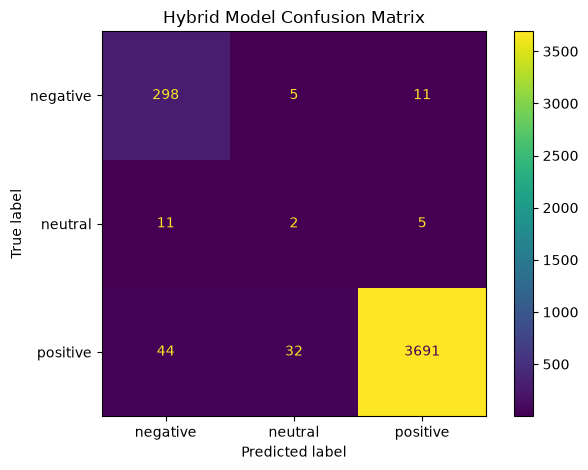

In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test, hybrid_predictions, labels=["negative", "neutral", "positive"],
    display_labels=["negative", "neutral", "positive"], values_format="d"
)
plt.title("Hybrid Model Confusion Matrix")
plt.tight_layout()
plt.show()


### Visualization 2: F1-score by Sentiment


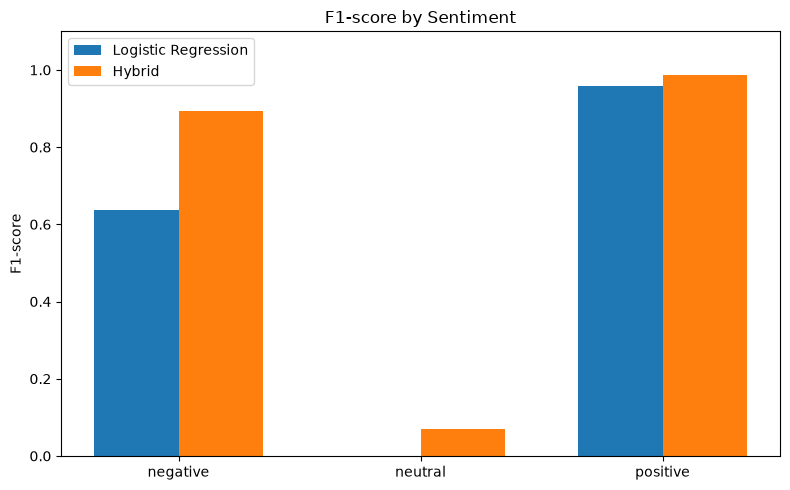

In [10]:

labels = ["negative", "neutral", "positive"]

lr_scores = classification_report(
    y_test, lr_predictions, output_dict=True, zero_division=0
)

hybrid_scores = classification_report(
    y_test, hybrid_predictions, output_dict=True, zero_division=0
)

x = np.arange(len(labels))
width = 0.35

lr_f1 = [lr_scores[label]["f1-score"] for label in labels]
hybrid_f1 = [hybrid_scores[label]["f1-score"] for label in labels]

plt.figure(figsize=(8, 5))
plt.bar(x - width/2, lr_f1, width, label="Logistic Regression")
plt.bar(x + width/2, hybrid_f1, width, label="Hybrid")

plt.xticks(x, labels)
plt.ylabel("F1-score")
plt.ylim(0, 1.1)
plt.title("F1-score by Sentiment")
plt.legend()
plt.tight_layout()
plt.show()

## 10. Conclusion

This project uses TF-IDF and Logistic Regression to classify hotel reviews. SIA is added using a simple mean-score rule and compared with Logistic Regression on the same test data. The results should be checked before deciding whether the hybrid method performs better, especially for the small neutral class.
